# Bab 7 – Support Vector Machines and Kernel Methods

## Ringkasan Bab
**Support Vector Machine (SVM)** mencari batas keputusan dengan **margin** terbesar antar kelas. Dengan **trik kernel**, SVM bisa
memisahkan data yang tidak terpisah secara linear. Bab ini membahas dasar SVM, fungsi kernel, penyetelan parameter `C` dan `gamma`,
SVM pada data berdimensi tinggi, evaluasi, dan tiga latihan praktik.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from sklearn.datasets import make_moons, make_circles, make_classification, load_breast_cancer
from sklearn.svm import SVC, LinearSVC, SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score
from sklearn.inspection import DecisionBoundaryDisplay

## 1. Pengantar SVM
Untuk data yang terpisah secara linear, SVM mencari hyperplane w·x + b = 0 dengan **margin** (jarak ke titik terdekat) maksimum,
yaitu meminimalkan ½‖w‖². Titik yang berada tepat di tepi margin disebut **support vector**, dan hanya titik inilah yang menentukan batas.

Untuk data yang tumpang tindih, **soft margin** mengizinkan beberapa kesalahan dengan penalti **C**:
* **C besar** → hukuman salah klasifikasi besar, margin sempit, berisiko overfitting.
* **C kecil** → margin lebar, lebih toleran, berisiko underfitting.

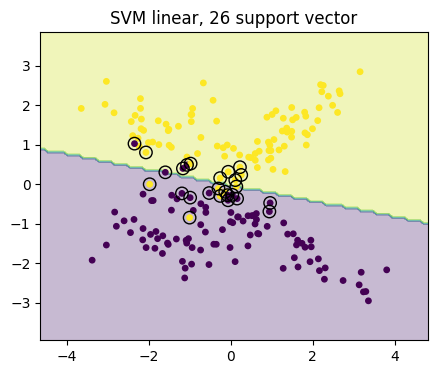

In [2]:
X, y = make_classification(n_samples=200, n_features=2, n_redundant=0, class_sep=1.2, random_state=3)
svm = SVC(kernel="linear", C=1).fit(X, y)
fig, ax = plt.subplots(figsize=(5, 4))
DecisionBoundaryDisplay.from_estimator(svm, X, ax=ax, alpha=.3, response_method="predict")
ax.scatter(X[:, 0], X[:, 1], c=y, s=15); ax.scatter(*svm.support_vectors_.T, s=80, facecolors="none", edgecolors="k")
ax.set_title(f"SVM linear, {len(svm.support_vectors_)} support vector"); plt.show()

## 2. Fungsi Kernel dan Aplikasinya
**Trik kernel** menghitung kemiripan dua titik seolah-olah data sudah dipetakan ke ruang berdimensi lebih tinggi, tanpa benar-benar
melakukan pemetaan itu.

| Kernel | Rumus K(x, x′) | Dipakai untuk |
|---|---|---|
| `linear` | x·x′ | data yang sudah terpisah linear, data teks |
| `poly` | (γ x·x′ + r)^d | interaksi polinomial |
| `rbf` | exp(−γ‖x − x′‖²) | pilihan umum untuk batas non-linear |
| `sigmoid` | tanh(γ x·x′ + r) | jarang dipakai |

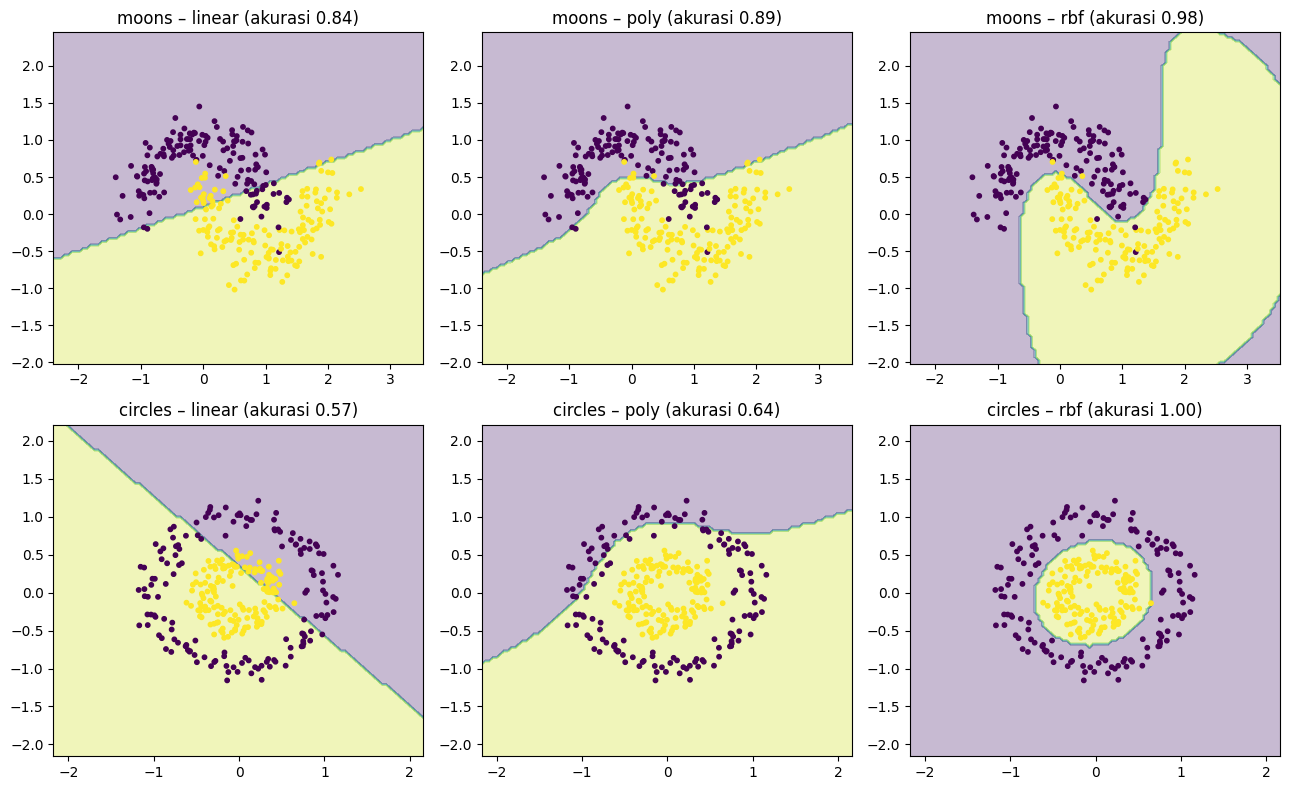

In [3]:
datasets = {"moons": make_moons(300, noise=.2, random_state=0), "circles": make_circles(300, noise=.1, factor=.4, random_state=0)}
fig, ax = plt.subplots(2, 3, figsize=(13, 8))
for i, (dn, (Xd, yd)) in enumerate(datasets.items()):
    for j, k in enumerate(["linear", "poly", "rbf"]):
        m = SVC(kernel=k, degree=3, gamma="scale").fit(Xd, yd)
        DecisionBoundaryDisplay.from_estimator(m, Xd, ax=ax[i, j], alpha=.3, response_method="predict")
        ax[i, j].scatter(Xd[:, 0], Xd[:, 1], c=yd, s=10); ax[i, j].set_title(f"{dn} – {k} (akurasi {m.score(Xd, yd):.2f})")
plt.tight_layout(); plt.show()

## 3. Menyetel Parameter SVM
* **C**: keseimbangan antara margin lebar dan kesalahan klasifikasi.
* **gamma** (kernel RBF): seberapa jauh pengaruh satu titik. Gamma besar → batas sangat lekuk-lekuk (overfitting); gamma kecil → batas terlalu halus.
* **degree** (kernel poly) dan **class_weight** (untuk kelas tidak seimbang).

Data **wajib di-scale** karena kernel bergantung pada jarak.

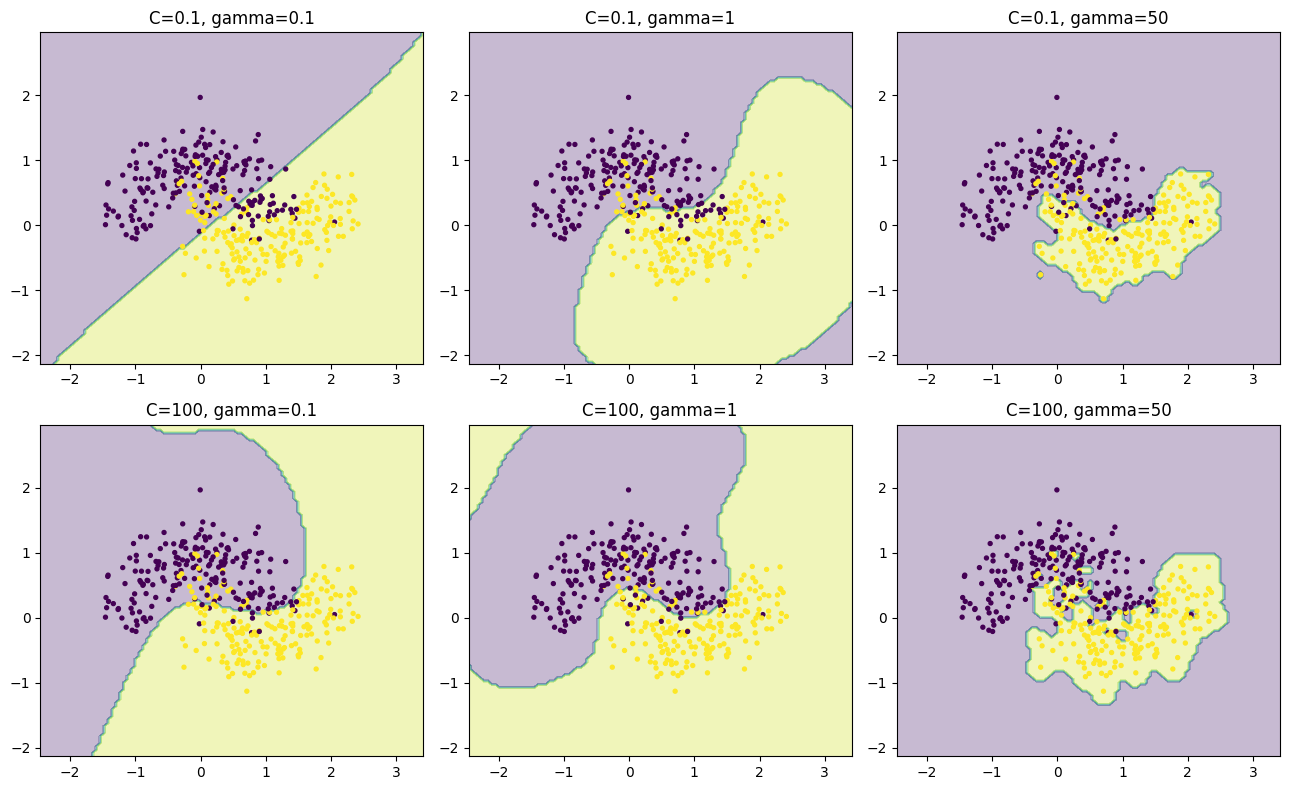

In [4]:
Xm, ym = make_moons(400, noise=.3, random_state=1)
fig, ax = plt.subplots(2, 3, figsize=(13, 8))
for i, C in enumerate([0.1, 100]):
    for j, g in enumerate([0.1, 1, 50]):
        m = SVC(kernel="rbf", C=C, gamma=g).fit(Xm, ym)
        DecisionBoundaryDisplay.from_estimator(m, Xm, ax=ax[i, j], alpha=.3, response_method="predict")
        ax[i, j].scatter(Xm[:, 0], Xm[:, 1], c=ym, s=8); ax[i, j].set_title(f"C={C}, gamma={g}")
plt.tight_layout(); plt.show()

## 4. SVM pada Ruang Berdimensi Tinggi
SVM cukup baik ketika jumlah fitur besar, bahkan lebih besar dari jumlah sampel, karena margin membatasi kompleksitas model.
Pada data berdimensi sangat tinggi, kernel **linear** sering sudah cukup dan jauh lebih cepat. Gunakan `LinearSVC`
untuk data besar, karena kompleksitas `SVC` berkisar antara O(n²) dan O(n³) terhadap jumlah sampel.

In [5]:
Xh, yh = make_classification(n_samples=600, n_features=500, n_informative=30, random_state=0)
Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(Xh, yh, test_size=.3, random_state=0)
for name, m in [("LinearSVC", LinearSVC(max_iter=20000)), ("SVC linear", SVC(kernel="linear")), ("SVC rbf", SVC(kernel="rbf"))]:
    p = make_pipeline(StandardScaler(), m); t = time.time(); p.fit(Xh_tr, yh_tr)
    print(f"{name:11s} akurasi uji = {p.score(Xh_te, yh_te):.3f} | waktu latih = {time.time()-t:.3f} dtk")

LinearSVC   akurasi uji = 0.644 | waktu latih = 0.029 dtk
SVC linear  akurasi uji = 0.644 | waktu latih = 0.041 dtk
SVC rbf     akurasi uji = 0.694 | waktu latih = 0.057 dtk


## 5. Mengevaluasi Model SVM
Gunakan cross-validation, confusion matrix, dan laporan klasifikasi. SVM tidak menghasilkan probabilitas secara default;
`probability=True` menambahkannya dengan kalibrasi internal (lebih lambat). SVM juga bisa untuk regresi lewat **SVR**
yang memakai tabung toleransi ε di sekitar garis prediksi.

CV akurasi: 0.965
              precision    recall  f1-score   support

   malignant       0.96      0.98      0.97        53
      benign       0.99      0.98      0.98        90

    accuracy                           0.98       143
   macro avg       0.98      0.98      0.98       143
weighted avg       0.98      0.98      0.98       143



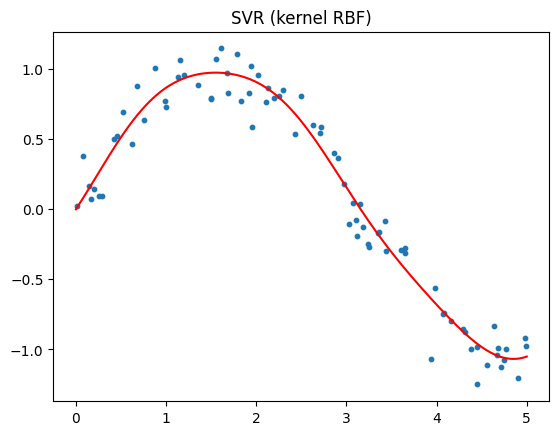

In [6]:
Xc, yc = load_breast_cancer(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=.25, stratify=yc, random_state=42)
model = make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, random_state=0)).fit(Xtr, ytr)
print("CV akurasi:", cross_val_score(model, Xtr, ytr, cv=5).mean().round(3))
print(classification_report(yte, model.predict(Xte), target_names=load_breast_cancer().target_names))

rng = np.random.default_rng(0); xs = np.sort(rng.uniform(0, 5, 80))[:, None]; ys = np.sin(xs).ravel() + rng.normal(0, .15, 80)
svr = SVR(kernel="rbf", C=10, epsilon=.1).fit(xs, ys)
plt.scatter(xs, ys, s=10); g = np.linspace(0, 5, 200)[:, None]; plt.plot(g, svr.predict(g), c="r"); plt.title("SVR (kernel RBF)"); plt.show()

## 6. Latihan Praktik

### Latihan 1 – Membangun Classifier SVM Sederhana

In [7]:
simple = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1, gamma="scale")).fit(Xtr, ytr)
print("Akurasi uji:", round(simple.score(Xte, yte), 3), "| jumlah support vector:", simple[-1].n_support_)

Akurasi uji: 0.979 | jumlah support vector: [50 46]


### Latihan 2 – SVM dengan Grid Search

In [8]:
gs = GridSearchCV(make_pipeline(StandardScaler(), SVC()),
                  {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1], "svc__kernel": ["rbf", "linear"]},
                  cv=5, n_jobs=-1).fit(Xtr, ytr)
print("Terbaik:", gs.best_params_, "| CV:", round(gs.best_score_, 3), "| uji:", round(gs.score(Xte, yte), 3))

Terbaik: {'svc__C': 10, 'svc__gamma': 0.001, 'svc__kernel': 'rbf'} | CV: 0.977 | uji: 0.979


### Latihan 3 – Visualisasi Batas Keputusan SVM
Dua fitur pertama dari data kanker payudara dipakai agar batas keputusan bisa digambar.

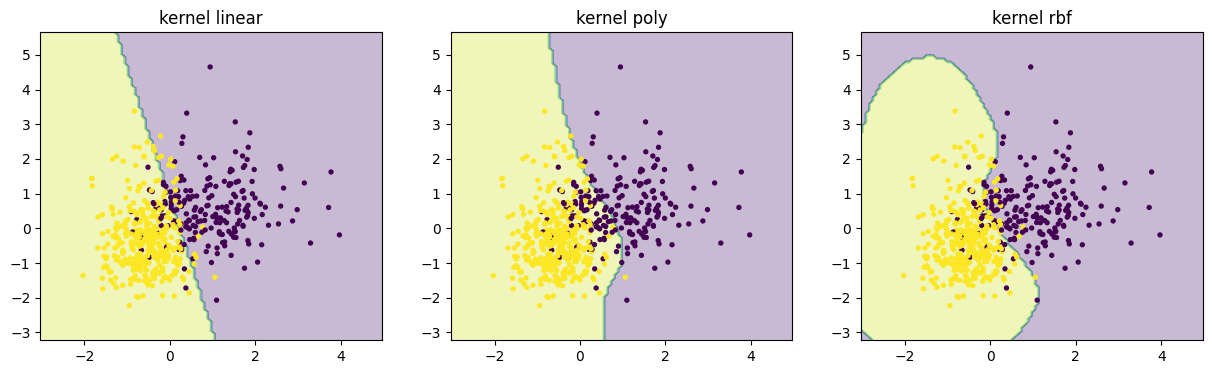

In [9]:
X2 = StandardScaler().fit_transform(Xc[:, :2])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, k in zip(ax, ["linear", "poly", "rbf"]):
    m = SVC(kernel=k).fit(X2, yc)
    DecisionBoundaryDisplay.from_estimator(m, X2, ax=a, alpha=.3, response_method="predict")
    a.scatter(X2[:, 0], X2[:, 1], c=yc, s=8); a.set_title(f"kernel {k}")
plt.show()

**Kesimpulan:** SVM kuat untuk data berukuran kecil sampai menengah. Selalu lakukan scaling, mulai dengan kernel RBF atau linear,
dan setel `C` serta `gamma` dengan cross-validation.